# Batalla Naval como problema de IA: entorno y agentes

Este notebook acompaña la aplicación del proyecto y muestra, paso a paso:

1. Los niveles de dificultad que configuran el entorno.
2. La creación de una instancia del entorno y sus principales atributos.
3. Sus métodos principales: percepción, acciones, transición, prueba de objetivo, semillas, instancias manuales y su guardado en JSON.
4. La aplicación de cada algoritmo sobre la misma partida y, por dentro, un paso concreto de cada uno.
5. La comparación de las dos heurísticas de MCTS y de todos los agentes con las métricas del proyecto.

## 1. Preparación

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from render_pygame import RenderizadorPygame
import pygame

from agents import AGENTES
from ambientes import AGUA, DESCONOCIDO, HUNDIDO, TOCADO, BatallaNavalEnv
from comparar import dibujar_comparacion, ejecutar_comparacion, resumen_agentes
from dificultad import NIVELES, ORDEN_NIVELES
from instancia import Instancia
from mcts_agent import AgenteMCTS
from utils import coord_a_texto

%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90
pd.set_option('display.precision', 2)
SEMILLA = 1000

La función `mostrar` dibuja un tablero con el mismo renderizador de la interfaz y lo muestra con matplotlib.
Con `revelado=True` se ve la flota oculta; `mapa` pinta el mapa de calor de un agente y `numeros`
el orden de los disparos.

In [2]:
render = RenderizadorPygame()


def mostrar(env, revelado=False, mapa=None, numeros=None, titulo=None, ax=None):
    render.configurar(env)
    superficie = render.dibujar(env, revelado, 10_000, mapa=mapa, numeros=numeros)
    imagen = pygame.surfarray.array3d(superficie).swapaxes(0, 1)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.imshow(imagen)
    ax.axis('off')
    if titulo:
        ax.set_title(titulo, fontsize=10)
    return ax

## 2. Niveles de dificultad

Cada nivel es un `ConfigDificultad` inmutable con el tamaño del tablero, la flota, el límite de disparos,
el ruido del sonar y si se informa qué barcos quedan. `casillas_barco` es el mínimo teórico de disparos
para ganar (una partida perfecta) y `densidad` la fracción del tablero ocupada por barcos.

In [3]:
pd.DataFrame([{
    'nivel': c.nombre,
    'tablero': f"{c.filas}x{c.columnas}",
    'flota': ", ".join(f"{n} ({L})" for n, L in c.flota.items()),
    'mínimo de disparos': c.casillas_barco,
    'densidad': round(c.densidad, 3),
    'límite de disparos': c.max_disparos or 'sin límite',
    'ruido del sonar': c.prob_ruido,
    'flota visible': c.mostrar_flota_restante,
} for c in (NIVELES[k] for k in ORDEN_NIVELES)]).set_index('nivel')

,tablero,flota,mínimo de disparos,densidad,límite de disparos,ruido del sonar,flota visible
nivel,,,,,,,
Fácil,6x6,"Crucero (3), Destructor (2), Lancha (2)",7,0.19,sin límite,0.00,True
Medio,8x8,"Acorazado (4), Crucero (3), Submarino (3), Des...",12,0.19,40,0.00,True
Difícil,10x10,"Portaaviones (5), Acorazado (4), Crucero (3), ...",17,0.17,55,0.00,False
Experto,12x12,"Portaaviones (5), Acorazado (4), Crucero (3), ...",17,0.12,80,0.06,False


## 3. Creación de una instancia del entorno

Se crea un entorno de nivel Medio con una semilla fija. La semilla determina dónde queda la flota:
con la misma semilla se obtiene siempre la misma partida, lo que permite comparar agentes de forma justa.

In [4]:
env = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA)

pd.Series({
    'config.nombre': env.config.nombre,
    'filas x columnas': f"{env.filas} x {env.columnas}",
    'seed': env.seed,
    'flota_config': env.flota_config,
    'turnos': env.turnos,
    'recompensa_acumulada': env.recompensa_acumulada,
    'done / ganado / agotado': (env.done, env.ganado, env.agotado),
    'disparos_restantes()': env.disparos_restantes(),
}, name='valor').to_frame()

,valor
config.nombre,Medio
filas x columnas,8 x 8
seed,1000
flota_config,"{'Acorazado': 4, 'Crucero': 3, 'Submarino': 3,..."
turnos,0
recompensa_acumulada,0
done / ganado / agotado,"(False, False, False)"
disparos_restantes(),40


### 3.1 Los barcos

Cada barco es un objeto Barco con su nombre, su longitud, las casillas que ocupa y los impactos recibidos.

In [5]:
pd.DataFrame([{
    'barco': b.nombre,
    'longitud': b.longitud,
    'casillas': " ".join(coord_a_texto(r, c) for r, c in b.posiciones),
    'impactos': b.impactos,
    'hundido': b.esta_hundido(),
} for b in env.barcos])

,barco,longitud,casillas,impactos,hundido
0,Acorazado,4,E2 F2 G2 H2,0,False
1,Crucero,3,B3 B4 B5,0,False
2,Submarino,3,C3 D3 E3,0,False
3,Destructor,2,B6 B7,0,False


### 3.2 Los dos tableros

El entorno guarda dos matrices del mismo tamaño:

- `tablero_oculto`: la verdad. 0 es agua y 1, 2, 3, ... identifican cada barco. El agente nunca la ve.
- `tablero_agente`: lo que el agente sabe. Empieza en `DESCONOCIDO` (-1) y se llena con
  `AGUA` (0), `TOCADO` (1) y `HUNDIDO` (2) a medida que dispara.

Por eso el problema es parcialmente observable.

tablero_oculto:
 [[0 0 0 0 0 0 0 0]
 [0 0 0 0 1 1 1 1]
 [0 2 3 3 3 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0]
 [0 4 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

tablero_agente:
 [[-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]
 [-1 -1 -1 -1 -1 -1 -1 -1]]


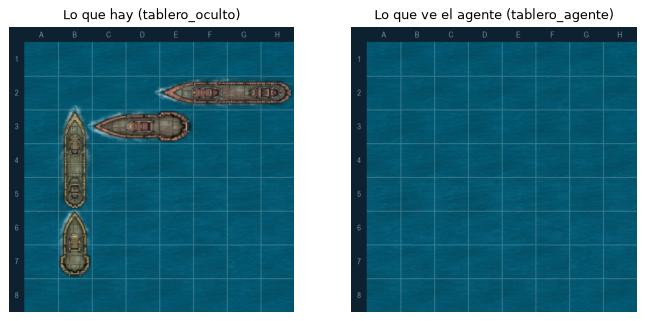

In [6]:
print("tablero_oculto:\n", env.tablero_oculto)
print("\ntablero_agente:\n", env.tablero_agente)

fig, ejes = plt.subplots(1, 2, figsize=(9, 4.5))
mostrar(env, revelado=True, titulo="Lo que hay (tablero_oculto)", ax=ejes[0])
mostrar(env, revelado=False, titulo="Lo que ve el agente (tablero_agente)", ax=ejes[1])
plt.show()

## 4. Métodos principales del entorno

### 4.1 Acciones aplicables y percepción

- `acciones_aplicables()` devuelve las casillas a las que aún no se ha disparado: el conjunto de acciones *A*.
- `para_sentidos()` devuelve la observación: lo único que un agente puede usar para decidir.

In [7]:
acciones = env.acciones_aplicables()
print(f"Acciones aplicables: {len(acciones)} (todas las casillas del tablero)")
print("Primeras:", [coord_a_texto(*a) for a in acciones[:6]], "...")

obs = env.para_sentidos()
{k: (v if k != 'tablero_agente' else f"matriz {v.shape}") for k, v in obs.items()}

Acciones aplicables: 64 (todas las casillas del tablero)
Primeras: ['A1', 'B1', 'C1', 'D1', 'E1', 'F1'] ...


{'tablero_agente': 'matriz (8, 8)',
 'barcos_vivos': ['Acorazado', 'Crucero', 'Submarino', 'Destructor'],
 'n_barcos_vivos': 4,
 'ultimo_feedback': None,
 'turnos': 0,
 'disparos_restantes': 40}

### 4.2 La transición con `step`

`step` ejecuta un disparo y devuelve `(observación, recompensa, done, info)`. Cada disparo cuesta **-1**,
así que maximizar la recompensa equivale a ganar con la menor cantidad de disparos.

Para mostrar los tres resultados posibles se dispara al agua y luego a todas las casillas del barco más
corto. Se usa el tablero oculto solo para elegir las casillas de esta demostración; un agente no puede hacerlo.

Disparo a A1: agua     | recompensa -1 | acumulada -1 | restantes 39
Disparo a B6: impacto  | recompensa -1 | acumulada -2 | restantes 38
Disparo a B7: hundido  | recompensa -1 | acumulada -3 | restantes 37

Barcos vivos según la observación: ['Acorazado', 'Crucero', 'Submarino']


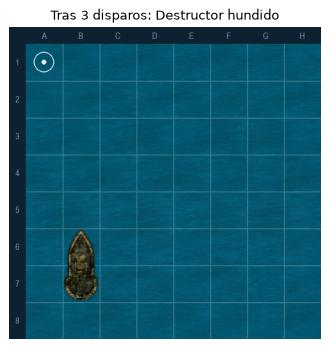

In [8]:
barco = min(env.barcos, key=lambda b: b.longitud)
agua = next((r, c) for r, c in env.acciones_aplicables() if env.tablero_oculto[r, c] == 0)

for accion in [agua] + barco.posiciones:
    obs, recompensa, done, info = env.step(accion)
    print(f"Disparo a {coord_a_texto(*accion)}: {obs['ultimo_feedback']['resultado']:8s}"
          f" | recompensa {recompensa} | acumulada {env.recompensa_acumulada}"
          f" | restantes {env.disparos_restantes()}")

print("\nBarcos vivos según la observación:", obs['barcos_vivos'])
mostrar(env, titulo=f"Tras {env.turnos} disparos: {barco.nombre} hundido")
plt.show()

Al hundir un barco, **todas** sus casillas pasan a `HUNDIDO` (2) en el tablero del agente:

In [9]:
env.tablero_agente

array([[ 0, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1],
       [-1,  2, -1, -1, -1, -1, -1, -1],
       [-1,  2, -1, -1, -1, -1, -1, -1],
       [-1, -1, -1, -1, -1, -1, -1, -1]])

### 4.3 Prueba de objetivo y fin de partida

`test_objetivo()` es verdadero cuando toda la flota está hundida (`ganado`). La partida también termina,
con derrota, si se agotan los disparos (`agotado`). `done` es cualquiera de los dos.
Aquí se termina la partida disparando a todos los barcos que quedan.

In [10]:
print("¿Objetivo cumplido?", env.test_objetivo())
for b in env.barcos:
    for casilla in b.posiciones:
        if env.tablero_agente[casilla] == DESCONOCIDO:
            env.step(casilla)

print("¿Objetivo cumplido?", env.test_objetivo(),
      f"| done={env.done}, ganado={env.ganado}, agotado={env.agotado}")
print(f"Disparos: {env.turnos} (el mínimo era {env.config.casillas_barco}),"
      f" recompensa acumulada {env.recompensa_acumulada}")

¿Objetivo cumplido? False
¿Objetivo cumplido? True | done=True, ganado=True, agotado=False
Disparos: 13 (el mínimo era 12), recompensa acumulada -13


### 4.4 `reset` y la semilla

`reset(seed)` reinicia el entorno. Con la misma semilla la flota queda exactamente en el mismo lugar;
con otra semilla cambia.

In [11]:
env.reset(seed=SEMILLA)
misma = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA)
otra = BatallaNavalEnv(config=NIVELES['medio'], seed=SEMILLA + 1)

print("Tras reset: turnos =", env.turnos, "| done =", env.done)
print("¿Misma flota con la misma semilla?", np.array_equal(env.tablero_oculto, misma.tablero_oculto))
print("¿Misma flota con otra semilla?   ", np.array_equal(env.tablero_oculto, otra.tablero_oculto))

Tras reset: turnos = 0 | done = False
¿Misma flota con la misma semilla? True
¿Misma flota con otra semilla?    False


### 4.5 Instancias personalizadas: colocar la flota a mano

Además de los niveles, el entorno acepta una **disposición manual** de la flota:
una lista `(barco, fila, columna, 'H'|'V')`. `validar_posicion` comprueba si un barco cabe sin salirse ni
cruzarse con otro. La clase `Instancia` (`instancia.py`) junta configuración y disposición; es lo que crea
el *Editor de instancias* de la interfaz y se puede guardar en JSON.

¿Cabe un barco de 4 en E7, horizontal? True
¿Cabe un barco de 4 en A1, vertical?   False (choca con el Acorazado)
¿Cabe un barco de 4 en G7, horizontal? False (se sale del tablero)
¿reset conserva la flota manual?      True


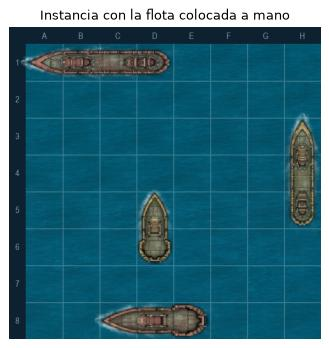

In [12]:
disposicion = [('Acorazado', 0, 0, 'H'), ('Crucero', 2, 7, 'V'),
               ('Submarino', 7, 2, 'H'), ('Destructor', 4, 3, 'V')]
manual = Instancia(config=NIVELES['medio'], disposicion=disposicion)
env_manual = manual.crear_env(seed=SEMILLA)

print("¿Cabe un barco de 4 en E7, horizontal?", env_manual.validar_posicion(6, 4, 4, 'H'))
print("¿Cabe un barco de 4 en A1, vertical?  ", env_manual.validar_posicion(0, 0, 4, 'V'), "(choca con el Acorazado)")
print("¿Cabe un barco de 4 en G7, horizontal?", env_manual.validar_posicion(6, 6, 4, 'H'), "(se sale del tablero)")

env_manual.reset(seed=SEMILLA + 99)
print("¿reset conserva la flota manual?     ", env_manual.disposicion_actual() == disposicion)
mostrar(env_manual, revelado=True, titulo="Instancia con la flota colocada a mano")
plt.show()

### 4.6 Guardar y cargar una instancia (JSON)

Una `Instancia` se guarda en un archivo JSON con `guardar(ruta)` y se recupera con `Instancia.cargar(ruta)`.
Es el formato que usa el *Editor de instancias* de la interfaz. El archivo contiene la configuración completa
del nivel (tablero, flota, límite de disparos, ruido, etc.) y la disposición de la flota; si la disposición es
`None`, la flota se coloca al azar según la semilla.

Al cargar, `Instancia.desde_dict` vuelve a crear el entorno para validarlo, así que un archivo con un barco
fuera del tablero o que choca con otro se rechaza con un `ValueError`. `firma()` es un resumen corto del
contenido: dos instancias iguales tienen la misma firma.

In [13]:
import os
import tempfile

ruta = os.path.join(tempfile.gettempdir(), 'instancia_manual.json')
manual.guardar(ruta)
with open(ruta, encoding='utf-8') as f:
    print(f.read())

cargada = Instancia.cargar(ruta)
env_cargado = cargada.crear_env(seed=SEMILLA)
print("¿Se recupera la misma instancia?   ", cargada == manual)
print("¿Misma firma?                      ", cargada.firma() == manual.firma(), f"({manual.firma()})")
print("¿Misma flota en el tablero oculto? ",
      np.array_equal(env_cargado.tablero_oculto, manual.crear_env(seed=SEMILLA).tablero_oculto))
print("¿Es manual? / id de registro:      ", cargada.manual, "/", cargada.id_registro)

# Un archivo con un barco fuera del tablero se rechaza al cargarlo
datos = manual.a_dict()
datos['disposicion'][0]['columna'] = 7      # el Acorazado (4 casillas) empezaría en H1 y se saldría
try:
    Instancia.desde_dict(datos)
except ValueError as e:
    print("\nInstancia rechazada:", e)

{
  "version": 1,
  "config": {
    "nombre": "Medio",
    "filas": 8,
    "columnas": 8,
    "flota": {
      "Acorazado": 4,
      "Crucero": 3,
      "Submarino": 3,
      "Destructor": 2
    },
    "colocacion": "uniforme",
    "permitir_adyacentes": true,
    "max_disparos": 40,
    "prob_ruido": 0.0,
    "mostrar_flota_restante": true
  },
  "disposicion": [
    {
      "barco": "Acorazado",
      "fila": 0,
      "columna": 0,
      "orientacion": "H"
    },
    {
      "barco": "Crucero",
      "fila": 2,
      "columna": 7,
      "orientacion": "V"
    },
    {
      "barco": "Submarino",
      "fila": 7,
      "columna": 2,
      "orientacion": "H"
    },
    {
      "barco": "Destructor",
      "fila": 4,
      "columna": 3,
      "orientacion": "V"
    }
  ]
}
¿Se recupera la misma instancia?    True
¿Misma firma?                       True (00544f)
¿Misma flota en el tablero oculto?  True
¿Es manual? / id de registro:       True / personalizada-00544f

Instancia rechazada:

### 4.7 Ruido del sonar (nivel Experto)

En Experto, con probabilidad `prob_ruido` el sonar **reporta mal** un disparo (agua ↔ impacto); el hundido
siempre es verdadero. `info['resultado_real']` guarda lo que pasó de verdad (solo para registro: los agentes
no lo ven). Se juegan 20 partidas al azar para contar cuántas veces mintió el sonar: en pocos disparos el
porcentaje observado fluctúa alrededor de `prob_ruido` y se acerca a él al acumular más.

In [14]:
errores = disparos = 0
PARTIDAS = 20
for i in range(PARTIDAS):
    env_ruido = BatallaNavalEnv(config=NIVELES['experto'], seed=SEMILLA + i)
    rng = np.random.default_rng(i)
    while not env_ruido.done:
        acciones = env_ruido.acciones_aplicables()
        obs, _, _, info = env_ruido.step(acciones[rng.integers(len(acciones))])
        errores += obs['ultimo_feedback']['resultado'] != info['resultado_real']
    disparos += env_ruido.turnos

print(f"{PARTIDAS} partidas | disparos: {disparos} | reportes falsos: {errores}"
      f" ({errores / disparos:.1%}; prob_ruido = {NIVELES['experto'].prob_ruido:.0%})")

20 partidas | disparos: 1600 | reportes falsos: 85 (5.3%; prob_ruido = 6%)


## 5. Los agentes

Todos los agentes heredan de `Agente` (`agents.py`) y comparten la misma interfaz:

- `restart(seed)`: reinicia el agente al empezar una partida.
- `make_decision(percepts)`: recibe la observación de `para_sentidos()` y devuelve la casilla a disparar.
- `estado_interno()`: describe la última decisión (mapa de calor, contadores, nodos y memoria).

El diccionario `AGENTES` es el registro que usan la interfaz, `evaluar.py` y `comparar.py`.

In [15]:
pd.DataFrame([{
    'clave': clave,
    'nombre': clase().name,
    'clase': clase.__name__,
    'archivo': clase.__module__ + '.py',
} for clave, clase in AGENTES.items()]).set_index('clave')

,nombre,clase,archivo
clave,,,
aleatorio,RandomAgent,RandomAgent,agents.py
caza,Caza-Remate,AgenteCazaRemate,agents.py
dqn,DQN,AgenteDQN,dqn_agent.py
mcts,MCTS (Paridad+Colineal),AgenteMCTS,mcts_agent.py
mcts_vecindad,MCTS (Vecindad),AgenteMCTSVecindad,mcts_agent.py
bayes,Red Bayesiana,AgenteBayesiano,bayes_agent.py


| Agente | Tipo | Idea |
|---|---|---|
| Aleatorio | No informado | Dispara a cualquier casilla desconocida. Es la línea base. |
| Caza-Remate | Informado (reglas heurísticas) | Caza por paridad de ajedrez; al tocar un barco remata sus vecinas, priorizando las alineadas. |
| DQN | Aprendizaje por refuerzo | Una red convolucional entrenada asigna un valor Q a cada casilla y elige la mayor. |
| MCTS (Paridad+Colineal) | Búsqueda en árbol Monte Carlo (POMCP) | Imagina flotas coherentes con lo observado, simula disparos y elige el más visitado. Poda con paridad y colinealidad. |
| MCTS (Vecindad) | Igual, con otra heurística | Solo considera las vecinas ortogonales de los impactos, sin paridad ni colinealidad. |
| Red Bayesiana | Inferencia probabilística | Calcula la probabilidad de barco en cada casilla marginalizando las posiciones posibles de cada barco (Noisy-OR) y dispara a la de mayor probabilidad. |

### 5.1 El ciclo percepción → decisión → acción

Así juega cualquier agente: percibe, decide y el entorno ejecuta. Es el mismo ciclo que usan la interfaz
y `evaluar.py`.

In [16]:
def jugar(clave, instancia, seed):
    agente = AGENTES[clave](config=instancia.config)
    env = instancia.crear_env(seed=seed)
    agente.restart(seed=seed)
    obs = env.para_sentidos()
    orden = {}
    while not env.done:
        accion = agente.make_decision(obs)
        obs, _, _, _ = env.step(accion)
        orden[tuple(int(v) for v in accion)] = env.turnos
    return agente, env, orden

### 5.2 Todos los agentes sobre la misma partida

Cada agente juega la misma instancia (nivel Medio, misma semilla, misma flota). Los números indican el
orden de los disparos; el mínimo posible es 12.

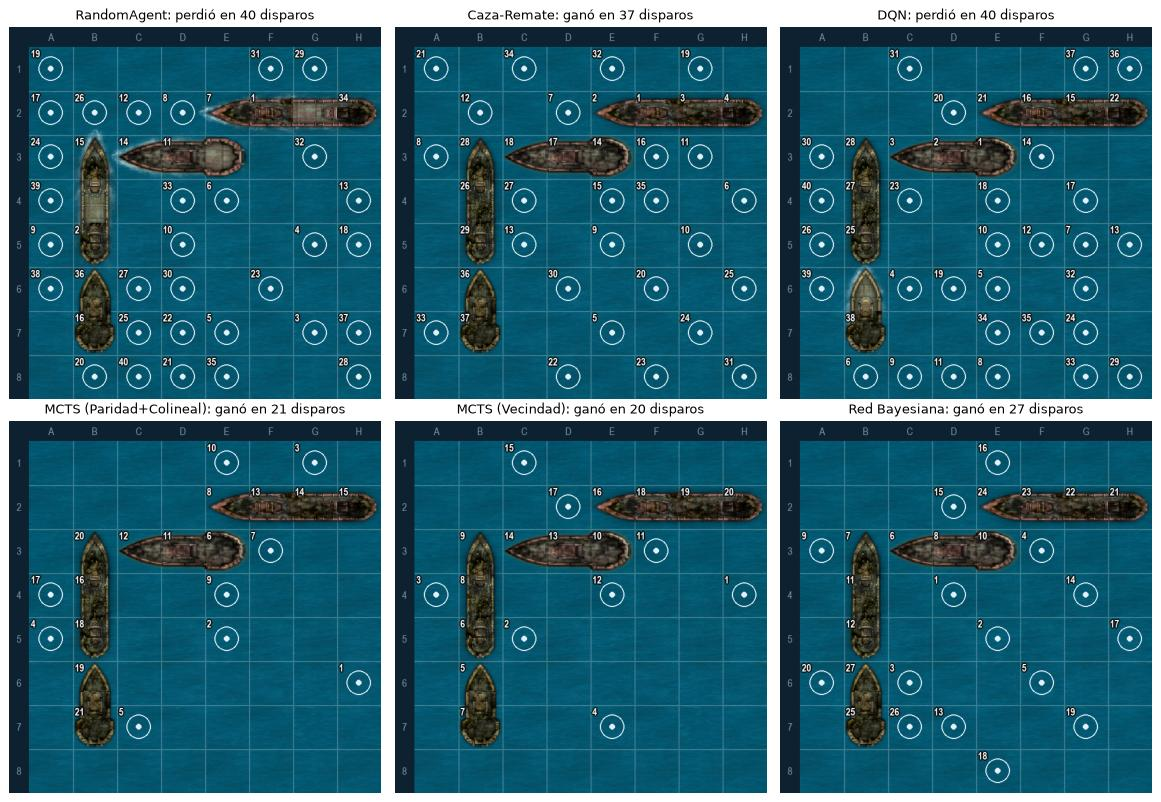

In [17]:
medio = Instancia.de_nivel('medio')
claves = list(AGENTES)
fig, ejes = plt.subplots(2, 3, figsize=(13, 9))
for ax, clave in zip(ejes.flat, claves):
    agente, env_fin, orden = jugar(clave, medio, SEMILLA)
    resultado = "ganó" if env_fin.ganado else "perdió"
    mostrar(env_fin, revelado=True, numeros=orden, ax=ax,
            titulo=f"{agente.name}: {resultado} en {env_fin.turnos} disparos")
for ax in ejes.flat[len(claves):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.3 Qué "piensa" cada agente

Se juegan los mismos 14 primeros disparos y, en el turno 15, se le pide a cada agente su decisión. El mapa de
calor es `estado_interno()['mapa']`: lo que el agente valora en cada casilla (puntaje, probabilidad o valor Q).
La tabla muestra sus contadores internos.

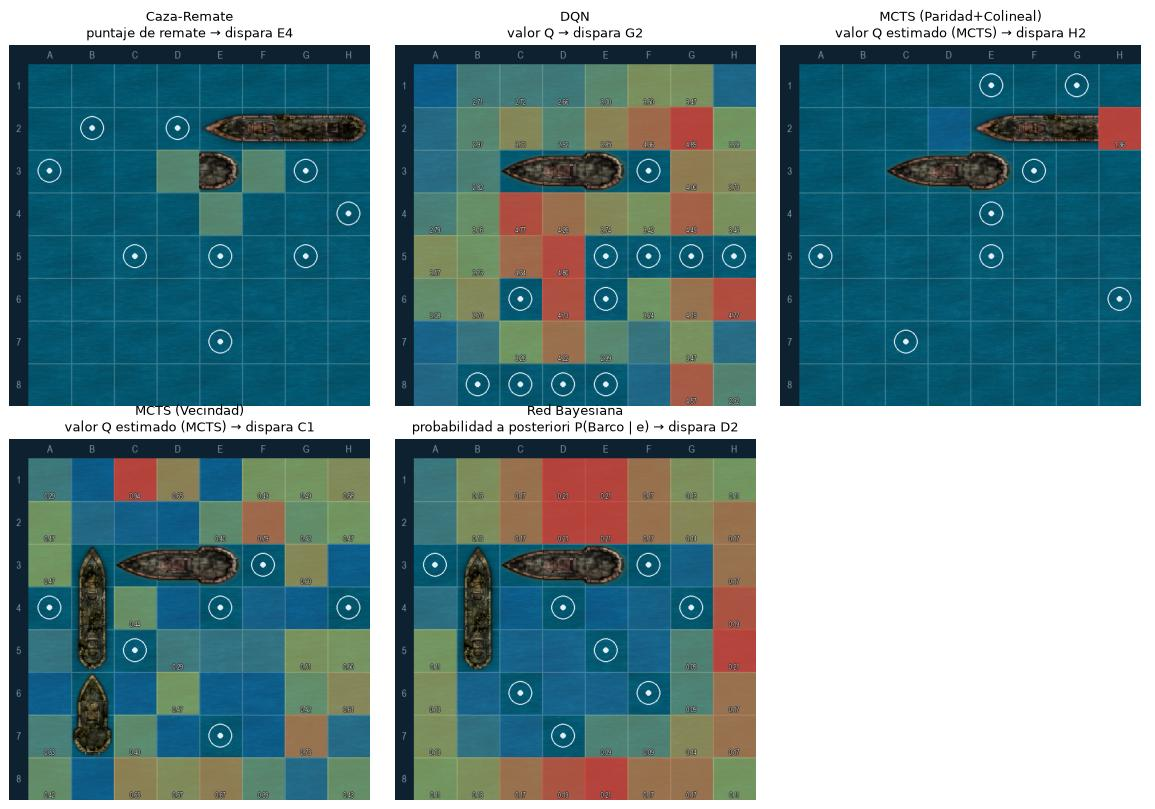

,decisión,nodos generados,nodos expandidos,memoria,detalle
agente,,,,,
Caza-Remate,E4,3,1,3,"modo: remate; candidatas: 3; regla activada: Remate ortogonal simple; candidatas de ""Remate ortogonal simple"": 3"
DQN,G2,50,1,113217,Q maximo: 4.886; Q medio: 3.355; parametros de la red: 113217
MCTS (Paridad+Colineal),H2,147,39,147,simulaciones: 200; candidatas exploradas: 2; nodos en el arbol: 147; acción elegida: H2; nodos expandidos: 39; nodos en frontera: 108; heuristica: paridad_colineal
MCTS (Vecindad),C1,201,54,201,simulaciones: 200; candidatas exploradas: 50; nodos en el arbol: 201; acción elegida: C1; nodos expandidos: 54; nodos en frontera: 147; heuristica: vecindad
Red Bayesiana,D2,192,89,153,P maxima: 0.2051; hipotesis evaluadas: 89; barcos en red: 2


In [18]:
def pensar(clave, instancia, seed, disparos_previos=14):
    agente = AGENTES[clave](config=instancia.config)
    env = instancia.crear_env(seed=seed)
    agente.restart(seed=seed)
    obs = env.para_sentidos()
    for _ in range(disparos_previos):
        obs, _, _, _ = env.step(agente.make_decision(obs))
    accion = agente.make_decision(obs)
    return agente, env, accion, agente.estado_interno()


inteligentes = [k for k in claves if k != 'aleatorio']
fig, ejes = plt.subplots(2, 3, figsize=(13, 9))
filas = []
for ax, clave in zip(ejes.flat, inteligentes):
    agente, env_t, accion, interno = pensar(clave, medio, SEMILLA)
    mostrar(env_t, mapa=interno['mapa'], ax=ax,
            titulo=f"{agente.name}\n{interno['tipo_mapa']} → dispara {coord_a_texto(*accion)}")
    filas.append({'agente': agente.name,
                  'decisión': coord_a_texto(*accion),
                  'nodos generados': interno.get('nodos_generados'),
                  'nodos expandidos': interno.get('nodos_expandidos'),
                  'memoria': interno.get('memoria'),
                  'detalle': "; ".join(f"{k}: {v}" for k, v in interno['info'].items())})
for ax in ejes.flat[len(inteligentes):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
pd.set_option('display.max_colwidth', None)
pd.DataFrame(filas).set_index('agente')

### 5.4 Dos heurísticas para MCTS

Ambos agentes son el mismo algoritmo (`AgenteMCTS`) con una heurística distinta para elegir qué disparos
explorar en el árbol:

- **Paridad + colineal**: prioriza las casillas que continúan una línea de impactos y, si no hay impactos,
  explora solo casillas de paridad (como un tablero de ajedrez).
- **Vecindad**: solo las vecinas ortogonales de los impactos; sin impactos, cualquier casilla libre.

Se comparan sobre las mismas 5 partidas de nivel Medio con `ejecutar_comparacion` de `comparar.py`.

In [19]:
df_heur, errores = ejecutar_comparacion(['mcts', 'mcts_vecindad'], medio, n=5, seed_base=SEMILLA)
resumen_agentes(df_heur)[['Victorias (%)', 'Disparos (media)', 'Disparos (desv.)', 'Eficiencia',
                          'Brecha al óptimo', 'Tiempo/jugada (ms)']]

,Victorias (%),Disparos (media),Disparos (desv.),Eficiencia,Brecha al óptimo,Tiempo/jugada (ms)
nombre,,,,,,
MCTS (Paridad+Colineal),100.0,25.8,4.53,0.48,13.8,151.85
MCTS (Vecindad),100.0,27.2,5.84,0.46,15.2,138.36


### 5.5 Los algoritmos por dentro

Para poder seguir cada algoritmo paso a paso, todos reciben el mismo escenario controlado, armado sobre la instancia manual de la
sección 4.5: dos impactos alineados en A1 y B1 (el Acorazado), un impacto suelto en D5 (el Destructor) y
cuatro disparos al agua (C3, F6, G7 y H8). Para MCTS (5.8) se usa una variante sin impactos alineados.

Barcos vivos: ['Acorazado', 'Crucero', 'Submarino', 'Destructor'] | disparos hechos: 7


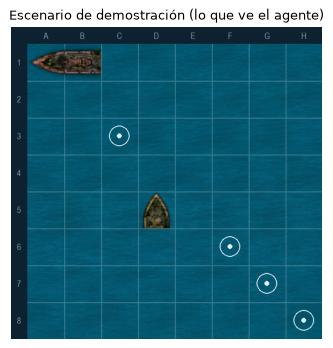

In [19]:
AGUA_DEMO = [(2, 2), (5, 5), (6, 6), (7, 7)]          # C3, F6, G7 y H8


def escenario(impactos):
    """Partida a medias sobre la instancia manual: los impactos indicados y cuatro disparos al agua."""
    e = manual.crear_env(seed=SEMILLA)
    for casilla in impactos + AGUA_DEMO:
        e.step(casilla)
    return e


env_esc = escenario([(0, 0), (0, 1), (4, 3)])        # impactos en A1, B1 y D5
obs_esc = env_esc.para_sentidos()
print("Barcos vivos:", obs_esc['barcos_vivos'], "| disparos hechos:", env_esc.turnos)
mostrar(env_esc, titulo="Escenario de demostración (lo que ve el agente)")
plt.show()

### 5.6 Caza-Remate (reglas heurísticas)

Tiene dos modos. Sin impactos pendientes está en **caza**: dispara solo a casillas con `fila + columna` par
(patrón de ajedrez), porque todo barco mide al menos 2 y por eso cruza siempre alguna de ellas. Con impactos
pendientes pasa a **remate**: puntúa las vecinas ortogonales de cada impacto (suma 1 por cada impacto vecino,
o 3 si la casilla prolonga una línea de dos impactos) y dispara a la de mayor puntaje.

Tablero vacío → {'modo': 'caza', 'candidatas': 32, 'regla activada': 'Caza por paridad de ajedrez', 'candidatas de "Caza por paridad de ajedrez"': 32}
Escenario     → {'modo': 'remate', 'candidatas': 7, 'regla activada': 'Remate colineal (impactos alineados)', 'candidatas de "Remate ortogonal simple"': 6, 'candidatas de "Remate colineal (impactos alineados)"': 1} | dispara C1


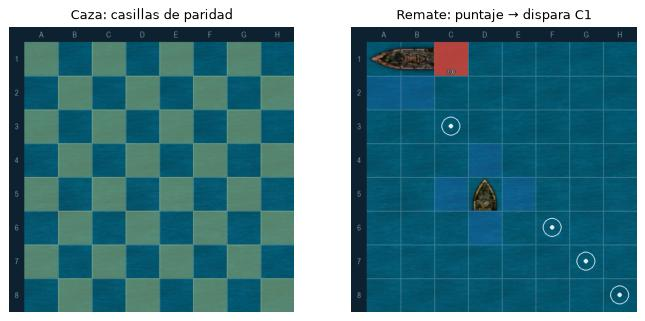

,puntaje,regla
casilla,,
C1,3.0,Remate colineal (impactos alineados)
A2,1.0,Remate ortogonal simple
B2,1.0,Remate ortogonal simple
D4,1.0,Remate ortogonal simple
D6,1.0,Remate ortogonal simple
C5,1.0,Remate ortogonal simple
E5,1.0,Remate ortogonal simple


In [20]:
caza = AGENTES['caza'](config=medio.config)
caza.restart(seed=SEMILLA)

# 1) Sin impactos: modo caza sobre un tablero vacío
vacio = manual.crear_env(seed=SEMILLA)
caza.make_decision(vacio.para_sentidos())
interno_caza = caza.estado_interno()
print("Tablero vacío →", interno_caza['info'])

# 2) Con impactos: modo remate sobre el escenario
accion = caza.make_decision(obs_esc)
interno = caza.estado_interno()
print("Escenario     →", interno['info'], "| dispara", coord_a_texto(*accion))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4.5))
mostrar(vacio, mapa=interno_caza['mapa'], ax=ejes[0], titulo="Caza: casillas de paridad")
mostrar(env_esc, mapa=interno['mapa'], ax=ejes[1], titulo=f"Remate: puntaje → dispara {coord_a_texto(*accion)}")
plt.show()

pd.DataFrame([{'casilla': coord_a_texto(r, c), 'puntaje': interno['mapa'][r, c],
               'regla': interno['leyenda'][clave]}
              for (r, c), clave in interno['categorias'].items()]
             ).sort_values('puntaje', ascending=False).set_index('casilla')

### 5.7 Red Bayesiana (inferencia probabilística)

Para cada barco vivo enumera todas las posiciones (horizontales y verticales) compatibles con lo observado:
descarta las que pisan agua o barcos hundidos y pondera más las que cubren impactos. Normaliza esos pesos y
obtiene `P(el barco k ocupa la casilla)`. Después combina los barcos con **Noisy-OR**:
`P(casilla ocupada) = 1 − Π(1 − P_k)`, y dispara a la casilla de mayor probabilidad.

El código siguiente muestra la marginal de cada barco, rehace el Noisy-OR a mano y comprueba que coincide con
el mapa posterior del agente.

Decisión: C1 | {'P maxima': 0.7243, 'hipotesis evaluadas': 315, 'barcos en red': 4}
         barco  posiciones compatibles
 Acorazado (4)                      62
   Crucero (3)                      78
 Submarino (3)                      78
Destructor (2)                      97
¿Noisy-OR manual = mapa del agente? True


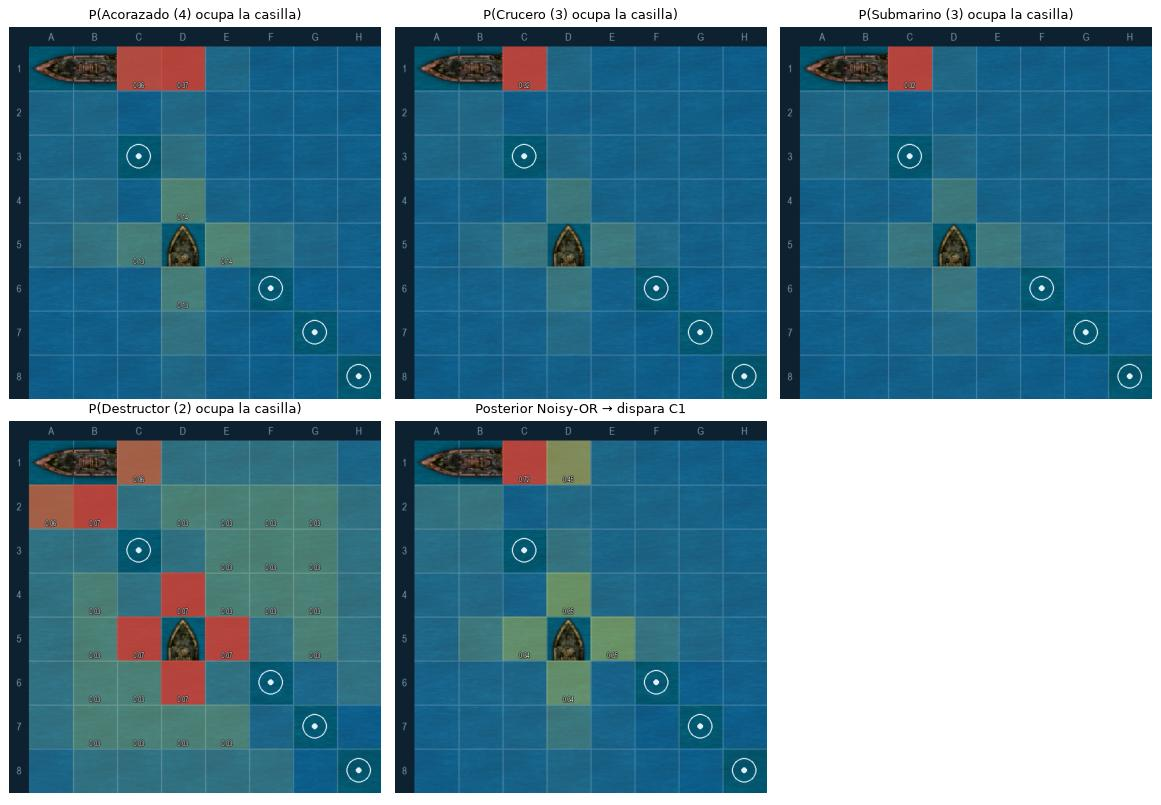

In [21]:
bayes = AGENTES['bayes'](config=medio.config)
bayes.restart(seed=SEMILLA)
accion = bayes.make_decision(obs_esc)
interno = bayes.estado_interno()
marginales = interno['marginales']

print("Decisión:", coord_a_texto(*accion), "|", interno['info'])
print(pd.DataFrame([{'barco': m['etiqueta'], 'posiciones compatibles': m['configs']}
                    for m in marginales]).to_string(index=False))

# Noisy-OR hecho a mano con las marginales: debe coincidir con el mapa posterior del agente
p_ningun_barco = np.ones(env_esc.tablero_agente.shape)
for m in marginales:
    p_ningun_barco *= 1.0 - np.nan_to_num(m['mapa'])
posterior = 1.0 - p_ningun_barco
libres = env_esc.tablero_agente == DESCONOCIDO
print("¿Noisy-OR manual = mapa del agente?", np.allclose(posterior[libres], interno['mapa'][libres]))

fig, ejes = plt.subplots(2, 3, figsize=(13, 9))
for ax, m in zip(ejes.flat, marginales):
    mostrar(env_esc, mapa=m['mapa'], ax=ax, titulo=f"P({m['etiqueta']} ocupa la casilla)")
mostrar(env_esc, mapa=interno['mapa'], ax=ejes.flat[len(marginales)],
        titulo=f"Posterior Noisy-OR → dispara {coord_a_texto(*accion)}")
for ax in ejes.flat[len(marginales) + 1:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.8 MCTS (búsqueda en árbol Monte Carlo)

Como la flota está oculta, el agente no puede buscar sobre el estado real. En cada una de sus `n_simulaciones`:

1. **Hipótesis**: genera al azar una flota completa coherente con lo observado (`_generar_hipotesis`), cubriendo primero los impactos.
2. **Selección y expansión**: baja hasta 3 niveles por el árbol eligiendo, entre las casillas candidatas (paridad y colinealidad, o vecindad), la de mayor UCB1 `Q + c·√(ln N / n)`; se detiene al crear un nodo nuevo.
3. **Simulación**: juega hasta 5 disparos más al azar sobre las candidatas, con recompensa 0 por agua, 0.7 por impacto y 1 por hundido, descontada con γ = 0.8.
4. **Retropropagación**: actualiza las visitas y el valor de las acciones del camino.

Al final dispara a la acción **más visitada** de la raíz.

Con dos impactos alineados la poda por colinealidad deja una sola candidata (C1) y no hay nada que comparar,
así que aquí se usa el mismo escenario **sin** el impacto en B1: quedan impactos sueltos en A1 y D5 y compiten
varias casillas vecinas. Primero, tres hipótesis de flota (las X son impactos conocidos y los círculos, agua):

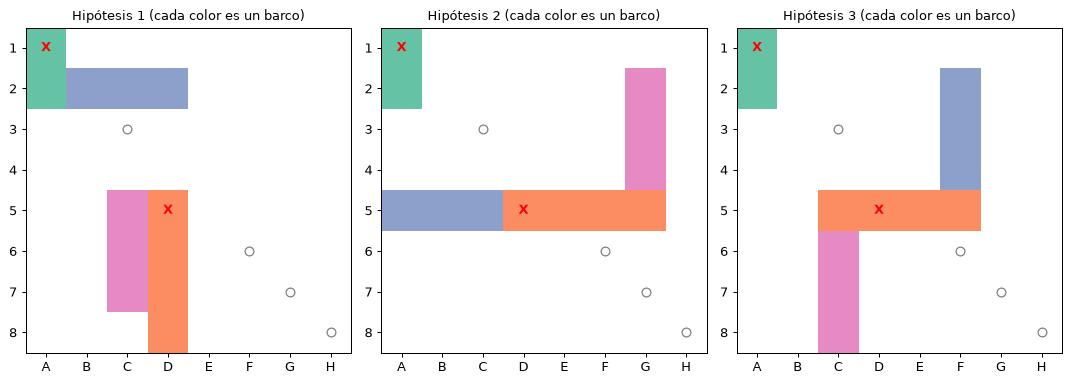

In [22]:
env_mcts = escenario([(0, 0), (4, 3)])               # impactos sueltos en A1 y D5
obs_mcts = env_mcts.para_sentidos()

mcts = AgenteMCTS(config=medio.config)
mcts.restart(seed=SEMILLA)
tablero_obs = obs_mcts['tablero_agente']
longitudes = [medio.config.flota[n] for n in obs_mcts['barcos_vivos']]
filas_t, cols_t = tablero_obs.shape

fig, ejes = plt.subplots(1, 3, figsize=(12, 4.2))
for k, ax in enumerate(ejes, start=1):
    hip, _ = mcts._generar_hipotesis(tablero_obs, longitudes)
    ax.imshow(np.ma.masked_equal(hip, 0), cmap='Set2', vmin=1, vmax=8)
    for (r, c), v in np.ndenumerate(tablero_obs):
        if v == TOCADO:
            ax.text(c, r, 'X', ha='center', va='center', color='red', fontweight='bold')
        elif v == AGUA:
            ax.plot(c, r, 'o', mfc='none', mec='gray', ms=7)
    ax.set_xticks(range(cols_t), [chr(65 + c) for c in range(cols_t)])
    ax.set_yticks(range(filas_t), [str(r + 1) for r in range(filas_t)])
    ax.set_title(f"Hipótesis {k} (cada color es un barco)", fontsize=10)
plt.tight_layout()
plt.show()

Ahora el árbol que resulta de las 200 simulaciones: la raíz, sus acciones más visitadas, las observaciones
posibles (agua / impacto / hundido) y las acciones del segundo nivel. `N` son las visitas y `Q` el valor medio.

Decisión: B1
{'simulaciones': 200, 'candidatas exploradas': 6, 'nodos en el arbol': 190, 'acción elegida': 'B1', 'nodos expandidos': 72, 'nodos en frontera': 118, 'heuristica': 'paridad_colineal'} 

Raíz [raiz]  N=200
  B1 [seleccionada]  N=52  Q=1.97
    agua [interno]  N=25
      D4 [interno]  N=6  Q=2.04
      E5 [interno]  N=5  Q=1.95
    impacto [interno]  N=18
      C1 [interno]  N=17  Q=2.14
    hundido [interno]  N=9
      D4 [interno]  N=3  Q=1.58
      C5 [interno]  N=2  Q=1.75
  E5 [interno]  N=37  Q=1.89
    agua [interno]  N=23
      A2 [interno]  N=6  Q=2.23
      D4 [interno]  N=5  Q=2.28
    impacto [interno]  N=12
      F5 [interno]  N=6  Q=1.97
      C5 [interno]  N=5  Q=1.97
    hundido [interno]  N=2
      B1 [frontera]  N=1  Q=1.75
  C5 [interno]  N=32  Q=1.84
    agua [interno]  N=19
      A2 [interno]  N=5  Q=2.01
      B1 [interno]  N=5  Q=1.98
    impacto [interno]  N=12
      B5 [interno]  N=6  Q=2.12
      E5 [interno]  N=5  Q=1.90
    hundido [frontera]  N=1

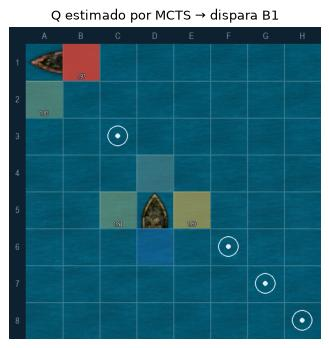

,visitas,Q medio
etiqueta,,
B1,52,1.97
E5,37,1.89
C5,32,1.84
A2,30,1.83
D6,25,1.76
D4,24,1.81


In [23]:
mcts.restart(seed=SEMILLA)                 # misma semilla que la tabla de más abajo
accion = mcts.make_decision(obs_mcts)
interno = mcts.estado_interno()
print("Decisión:", coord_a_texto(*accion))
print(interno['info'], "\n")


def imprimir_arbol(nodo, nivel=0):
    q = '' if nodo['Q'] is None else f"  Q={nodo['Q']:.2f}"
    print('  ' * nivel + f"{nodo['etiqueta']} [{nodo['tipo']}]  N={nodo['N']}{q}")
    for hijo in nodo['hijos']:
        imprimir_arbol(hijo, nivel + 1)


imprimir_arbol(interno['arbol'])

mostrar(env_mcts, mapa=interno['mapa'], titulo=f"Q estimado por MCTS → dispara {coord_a_texto(*accion)}")
plt.show()
pd.DataFrame(interno['acciones_raiz']).rename(columns={'N': 'visitas', 'Q': 'Q medio'}).set_index('etiqueta')

Más simulaciones concentran las visitas en la mejor acción y hacen la decisión más estable, a cambio de más tiempo por jugada:

In [24]:
filas = []
for n in (10, 50, 200, 800):
    ag = AgenteMCTS(config=medio.config, n_simulaciones=n)
    ag.restart(seed=SEMILLA)
    a = ag.make_decision(obs_mcts)
    est = ag.estado_interno()
    filas.append({'simulaciones': n, 'decisión': coord_a_texto(*a),
                  'visitas de la elegida': est['acciones_raiz'][0]['N'],
                  'candidatas exploradas': est['info']['candidatas exploradas'],
                  'nodos en el árbol': est['info']['nodos en el arbol']})
pd.DataFrame(filas).set_index('simulaciones')

,decisión,visitas de la elegida,candidatas exploradas,nodos en el árbol
simulaciones,,,,
10,D4,2,6,11
50,A2,12,6,51
200,B1,52,6,190
800,B1,344,6,471


### 5.9 DQN (aprendizaje por refuerzo)

Este agente **no busca ni razona sobre flotas**: aprendió, jugando miles de partidas, una función de valor
`Q(estado, casilla)`.

- **Entrada**: `codificar(tablero)` convierte el tablero que ve el agente en 4 canales binarios (desconocido, agua, tocado, hundido).
- **Red**: `RedQ` es totalmente convolucional (cuatro capas de 3×3 y una de 1×1) y entrega un valor Q por casilla; por eso un mismo modelo sirve para cualquier tamaño de tablero.
- **Decisión**: se enmascaran con −∞ las casillas ya disparadas y se dispara a la de mayor Q.
- **Entrenamiento** (`entrenar_dqn.py`, por ejemplo `python entrenar_dqn.py --nivel medio --episodios 3000`): memoria de repetición, red objetivo, Double DQN, ε-greedy y una recompensa moldeada que solo se usa para entrenar (agua −1, impacto +1, hundido +3 y −5 si se pierde por límite de disparos). El entorno sigue dando −1 por disparo.

Entrada codificada: (4, 8, 8) (canales: desconocido, agua, tocado, hundido)
Parámetros de la red: 113217
Casillas enmascaradas (-inf): 7 | disparos ya hechos: 7
Casilla de mayor Q: E2 (Q = 7.578)
¿Coincide con AgenteDQN.make_decision? True


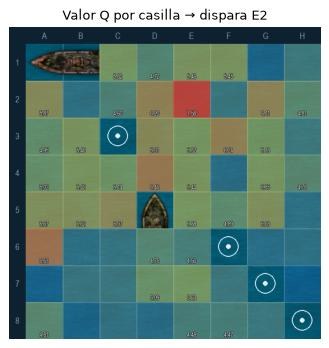

In [25]:
try:
    import torch
    from dqn_agent import cargar_modelo, codificar, q_enmascarado, ruta_modelo
except ImportError:
    torch = None
    print("PyTorch no está instalado: se omite el ejemplo del DQN.")

if torch is not None:
    estado = codificar(obs_esc['tablero_agente'])
    print("Entrada codificada:", estado.shape, "(canales: desconocido, agua, tocado, hundido)")

    red = cargar_modelo(ruta_modelo('medio'))
    print("Parámetros de la red:", sum(p.numel() for p in red.parameters()))

    with torch.no_grad():
        x = torch.from_numpy(estado).float().unsqueeze(0)
        q = q_enmascarado(red(x), x)[0].numpy()

    print("Casillas enmascaradas (-inf):", int(np.isinf(q).sum()), "| disparos ya hechos:", env_esc.turnos)
    accion = divmod(int(np.argmax(q)), q.shape[1])
    print("Casilla de mayor Q:", coord_a_texto(*accion), f"(Q = {q[accion]:.3f})")

    if 'dqn' in AGENTES:
        agente_dqn = AGENTES['dqn'](config=medio.config)
        agente_dqn.restart(seed=SEMILLA)
        print("¿Coincide con AgenteDQN.make_decision?", agente_dqn.make_decision(obs_esc) == accion)

    mostrar(env_esc, mapa=np.where(np.isfinite(q), q, np.nan),
            titulo=f"Valor Q por casilla → dispara {coord_a_texto(*accion)}")
    plt.show()

La curva de aprendizaje del nivel Medio sale de `models/dqn_medio_log.csv`, que escribe `entrenar_dqn.py`
(una fila por episodio de entrenamiento). Se suaviza con una media móvil de 100 episodios.

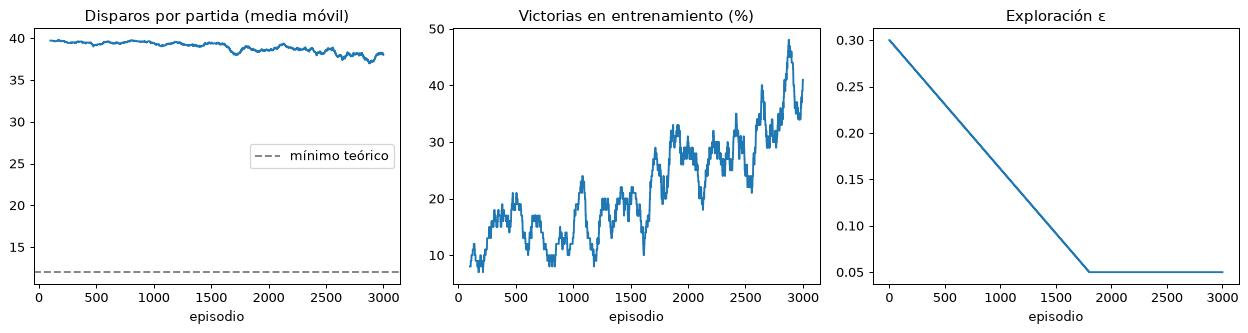

In [26]:
log = pd.read_csv('models/dqn_medio_log.csv')
ventana = 100

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
ejes[0].plot(log['episodio'], log['disparos'].rolling(ventana).mean())
ejes[0].axhline(NIVELES['medio'].casillas_barco, color='gray', ls='--', label='mínimo teórico')
ejes[0].set(title='Disparos por partida (media móvil)', xlabel='episodio')
ejes[0].legend()
ejes[1].plot(log['episodio'], 100 * log['ganado'].rolling(ventana).mean())
ejes[1].set(title='Victorias en entrenamiento (%)', xlabel='episodio')
ejes[2].plot(log['episodio'], log['epsilon'])
ejes[2].set(title='Exploración ε', xlabel='episodio')
plt.tight_layout()
plt.show()

## 6. Comparación de todos los agentes

La pestaña **Comparar** de la interfaz usa exactamente estas funciones. Todos los agentes juegan las mismas
partidas: la partida *i* usa la semilla `SEMILLA + i`. Aquí se usan 5 partidas para que el notebook sea rápido;
para el análisis del informe conviene usar más (por ejemplo `python evaluar.py --episodios 100`).

In [27]:
df, errores = ejecutar_comparacion(claves, medio, n=5, seed_base=SEMILLA)
if errores:
    print("No se pudieron evaluar:", errores)
tabla = resumen_agentes(df)
tabla

,Partidas,Victorias (%),Disparos (media),Disparos (desv.),Disparos (mín.),Disparos (máx.),Eficiencia,Óptimas (%),Brecha al óptimo,Recompensa acum.,Tiempo/jugada (ms),Tiempo/partida (s),Evaluaciones,Memoria máx.,Tiempo CPU (s),Nodos generados,Nodos expandidos
nombre,,,,,,,,,,,,,,,,,
RandomAgent,5,0.0,40.0,0.00,40,40,NaN,0.0,NaN,-40.0,0.08,3.28e-03,0.0,0,3.13e-03,0.0,0.0
Caza-Remate,5,100.0,37.6,1.36,36,40,0.32,0.0,25.6,-37.6,0.11,4.04e-03,505.0,32,6.25e-03,505.0,42.8
DQN,5,40.0,38.6,2.33,34,40,0.33,0.0,24.5,-38.6,1.04,4.01e-02,1742.0,113217,8.13e-02,1742.0,38.6
MCTS (Paridad+Colineal),5,100.0,25.8,4.53,21,33,0.48,0.0,13.8,-25.8,182.99,4.74e+00,34666.2,201,4.47e+00,4147.4,823.4
MCTS (Vecindad),5,100.0,27.2,5.84,20,37,0.46,0.0,15.2,-27.2,170.19,4.65e+00,35444.0,201,4.28e+00,4782.8,1336.0
Red Bayesiana,5,100.0,30.4,3.67,27,37,0.40,0.0,18.4,-30.4,0.97,2.94e-02,4404.0,448,2.50e-02,7814.4,4404.0


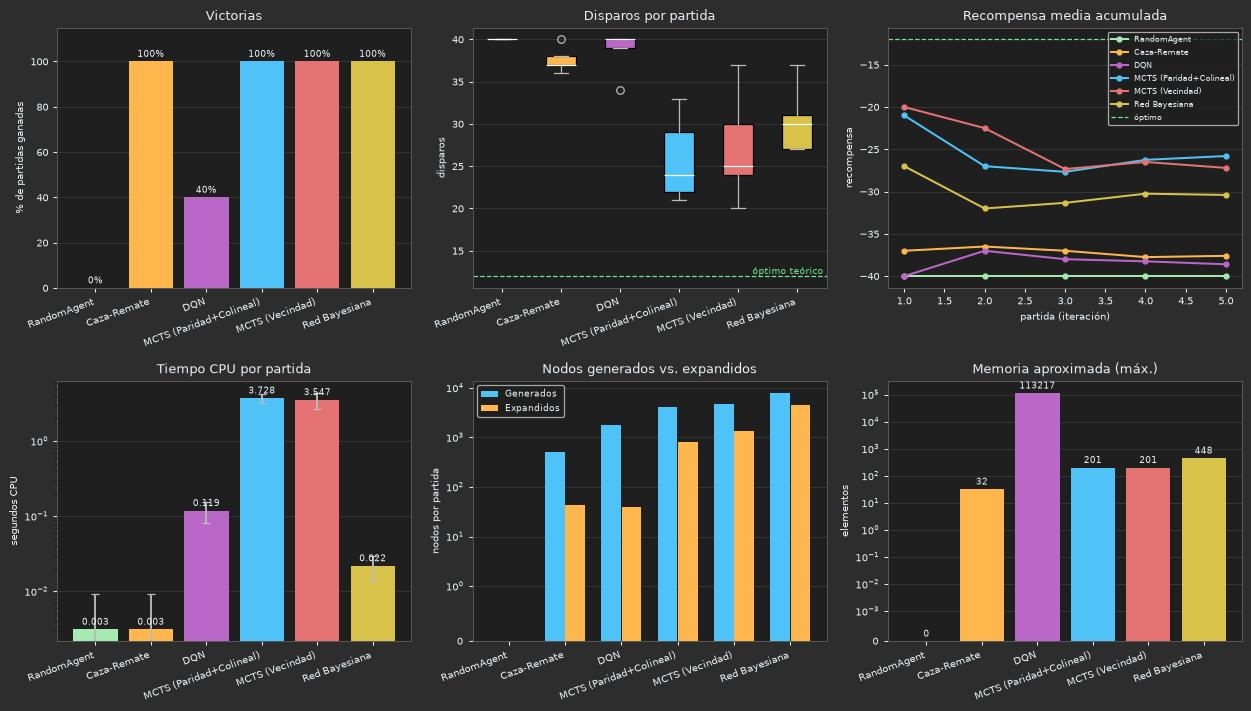

In [21]:
fig = plt.figure(figsize=(14, 8))
dibujar_comparacion(fig, df, minimo=medio.config.casillas_barco)
plt.show()

## 7. Resumen

- El entorno es **secuencial, discreto, estático y parcialmente observable**; en Experto la observación es
  además **estocástica** por el ruido del sonar.
- `para_sentidos()` es la única información de los agentes, `step()` es la transición con recompensa -1 por
  disparo y `test_objetivo()` comprueba que la flota esté hundida.
- La semilla y la clase `Instancia` permiten repetir exactamente una partida, por eso la comparación es justa; además una instancia se puede guardar y cargar en JSON.
- Cada algoritmo usa una idea distinta sobre la misma observación: reglas (Caza-Remate), inferencia probabilística (Red Bayesiana), simulación y árbol de búsqueda (MCTS) y una función de valor aprendida (DQN).
- Todos los agentes comparten la interfaz `restart` / `make_decision` / `estado_interno`, y se comparan con
  las mismas métricas que la interfaz gráfica (`evaluar.py` y `comparar.py`).

Para ver el proceso animado, paso a paso y con el árbol de MCTS, ejecuta `python app_qt.py`.